## Análisis de modelos

## Regresión lineal

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

In [17]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


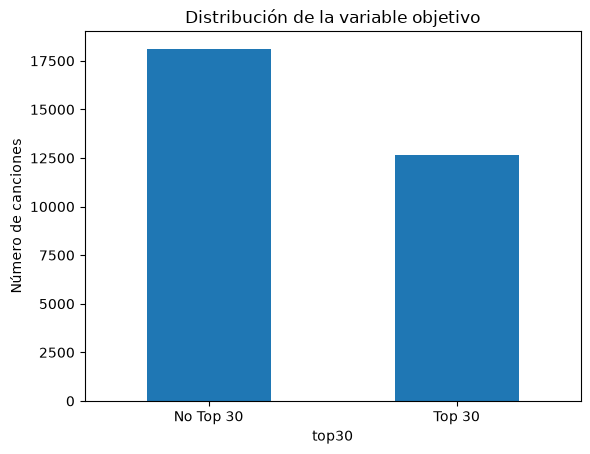

In [18]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [19]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(18462, 13) (6154, 13) (6155, 13)
En train: 41.14 % En validación:  41.14 %   en test: 41.14 %


In [20]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(18462, 13)

Columnas con nulos:
spotify_track_duration_ms    2175
spotify_track_explicit       2175
danceability                 2215
key                          2215
loudness                     2215
mode                         2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
time_signature               2215
dtype: int64


## Aplicamos el análisis en X_train

In [21]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
loudness                     2215
key                          2215
mode                         2215
time_signature               2215
spotify_track_duration_ms    2175
spotify_track_explicit       2175
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6010645657659875), 'speechiness': np.float64(0.0900256662768511), 'instrumentalness': np.float64(0.0328892274376808), 'tempo': np.float64(120.93728928417553), 'loudness': np.float64(-8.166), 'key': np.float64(0.

## Rellenamos nulos en X_val 

In [22]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 762
speechiness                  762
instrumentalness             762
tempo                        762
loudness                     762
key                          762
mode                         762
time_signature               762
spotify_track_duration_ms    753
spotify_track_explicit       753
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


## Rellenamos nulos en X_test

In [23]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 732
speechiness                  732
instrumentalness             732
tempo                        732
loudness                     732
key                          732
mode                         732
time_signature               732
spotify_track_duration_ms    722
spotify_track_explicit       722
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


In [9]:

print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [10]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())


['performer_"Weird Al" Yankovic' "performer_'N Sync"
 "performer_'N Sync & Gloria Estefan" ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 9377
Nulos después del OneHotEncoder:
Train: 0
Validation: 0


In [11]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc = scaler.transform(X_val)

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_esc, y_train) 

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## Evaluar en train y en val

In [12]:
pred_tonto = np.zeros(len(y_val), dtype=int)
print('Accuracy del modelo "nunca entra" :', round(accuracy_score(y_val, pred_tonto), 3))
print('Recall del modelo "nunca entra"  :', round(recall_score(y_val, pred_tonto), 3))

Accuracy del modelo "nunca entra" : 0.589
Recall del modelo "nunca entra"  : 0.0


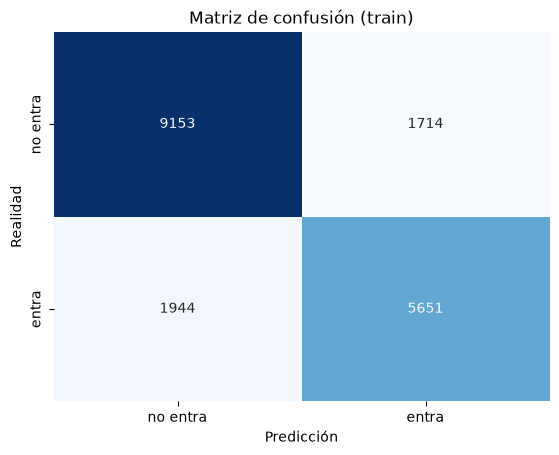

scikit-learn -> accuracy 0.802   precision 0.767   recall 0.744   F1 0.755
AUC: 0.897


In [13]:
pred_train = modelo.predict(X_train_esc)     
prob_train = modelo.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

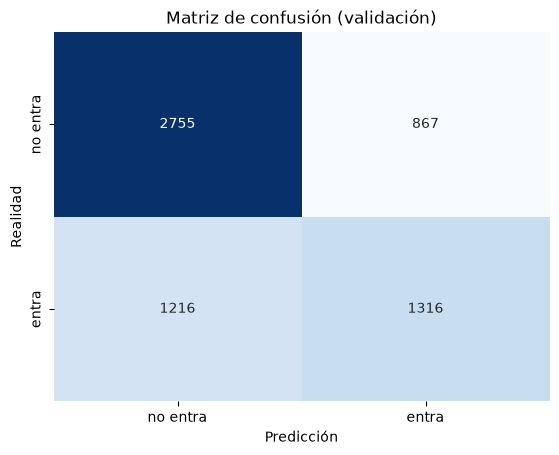

scikit-learn -> accuracy 0.662   precision 0.603   recall 0.520   F1 0.558
AUC: 0.673


In [14]:
pred_val = modelo.predict(X_val_esc)     
prob_val = modelo.predict_proba(X_val_esc)[:, 1]  

cm = confusion_matrix(y_val, pred_val)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (validación)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_val, pred_val):.3f}   '
      f'precision {precision_score(y_val, pred_val):.3f}   '
      f'recall {recall_score(y_val, pred_val):.3f}   F1 {f1_score(y_val, pred_val):.3f}')

print('AUC:', round(roc_auc_score(y_val, prob_val), 3))

## Tomando decidiones:
- Viendo los resultados nos dimos cuenta de que el modelo tenía sobreajuste. Investigando descubrimos que se debía a la cantidad de cantantes que se generaban iguales después del OneHotEncoder y el modelo daba mucha importancia y basaba toda su predicción en esta columna de tal forma que memorizaba las canciones.

Las soluciones que tomamos fueron:

- Reduccir el número de cantantes sustituyendo los de poca relevancia por la categoria 'Otros'.
- Al perder mucho dinero en los falsos positivos prevalecer que diga que una canción no entra aunque luego se equivoque.
- Modificar C (hiperparámetro de LogisticRegression -> A más pequeño es C más penaliza al modelo por ser complejo).

In [24]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]

encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist", 
    min_frequency=30,
    drop="first",
    sparse_output=False
)
encoder.fit(X_train[texto])
nombres = encoder.get_feature_names_out(texto)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val   = pd.DataFrame(encoder.transform(X_val[texto]),   columns=nombres, index=X_val.index)
cat_test  = pd.DataFrame(encoder.transform(X_test[texto]),  columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val   = pd.concat([X_val.drop(columns=texto),   cat_val],   axis=1)
X_test  = pd.concat([X_test.drop(columns=texto),  cat_test],  axis=1)

print("Columnas del modelo:", X_train.shape[1]) 
print("Nulos -> Train:", X_train.isna().sum().sum(),
      "| Val:", X_val.isna().sum().sum(),
      "| Test:", X_test.isna().sum().sum())   


Columnas del modelo: 154
Nulos -> Train: 0 | Val: 0 | Test: 0


c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [25]:

scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc   = scaler.transform(X_val)
X_test_esc  = scaler.transform(X_test)

print(f"{'C':<8}{'AUC train':<12}{'AUC val':<12}{'Diferencia'}")
for C in [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]:
    m = LogisticRegression(C=C, max_iter=2000)
    m.fit(X_train_esc, y_train)
    auc_tr = roc_auc_score(y_train, m.predict_proba(X_train_esc)[:, 1])
    auc_va = roc_auc_score(y_val,   m.predict_proba(X_val_esc)[:, 1])
    print(f"{C:<8}{auc_tr:<12.3f}{auc_va:<12.3f}{auc_tr - auc_va:.3f}")

C       AUC train   AUC val     Diferencia
0.0005  0.673       0.666       0.007
0.001   0.675       0.668       0.006
0.005   0.678       0.671       0.006
0.01    0.678       0.671       0.007
0.05    0.679       0.671       0.007
0.1     0.679       0.671       0.007
0.5     0.679       0.671       0.007
1       0.679       0.671       0.007


## Nos quedamos el mejor C

In [ ]:
C_elegido = 0.01 

modelo2 = LogisticRegression(C=C_elegido, max_iter=2000)
modelo2.fit(X_train_esc, y_train)

probs_val = modelo2.predict_proba(X_val_esc)[:, 1]

print(f"{'umbral':<9}{'precisión':<11}{'recall':<9}{'canciones aprobadas'}")
for umbral in [0.40, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:
    pred = (probs_val >= umbral).astype(int)
    print(f"{umbral:<9.2f}{precision_score(y_val, pred, zero_division=0):<11.3f}"
          f"{recall_score(y_val, pred):<9.3f}{pred.sum()}")

umbral   precisión  recall   canciones aprobadas
0.40     0.557      0.505    2295
0.50     0.775      0.261    853
0.55     0.805      0.244    768
0.60     0.825      0.233    716
0.65     0.839      0.224    675
0.70     0.849      0.211    628
0.75     0.857      0.184    545
0.80     0.864      0.143    419


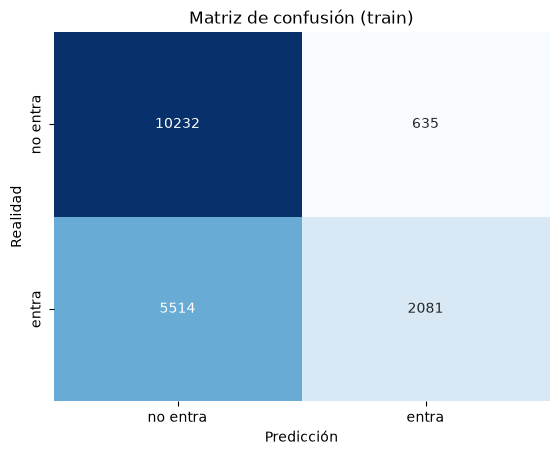

scikit-learn -> accuracy 0.667   precision 0.766   recall 0.274   F1 0.404
AUC: 0.678


In [ ]:
pred_train = modelo2.predict(X_train_esc)     
prob_train = modelo2.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

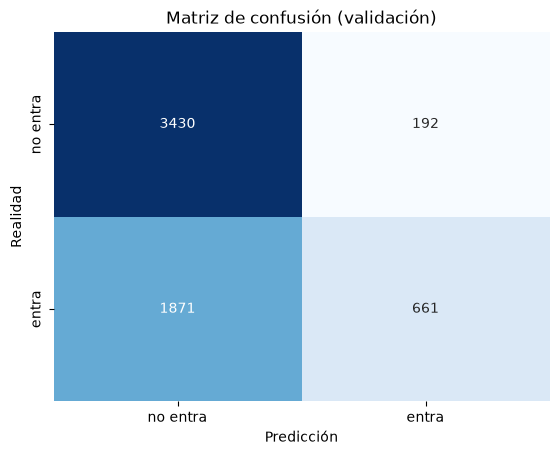

scikit-learn -> accuracy 0.665   precision 0.775   recall 0.261   F1 0.391
AUC: 0.671


In [ ]:
pred_val = modelo2.predict(X_val_esc)     
prob_val = modelo2.predict_proba(X_val_esc)[:, 1]  

cm = confusion_matrix(y_val, pred_val)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (validación)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_val, pred_val):.3f}   '
      f'precision {precision_score(y_val, pred_val):.3f}   '
      f'recall {recall_score(y_val, pred_val):.3f}   F1 {f1_score(y_val, pred_val):.3f}')

print('AUC:', round(roc_auc_score(y_val, prob_val), 3))

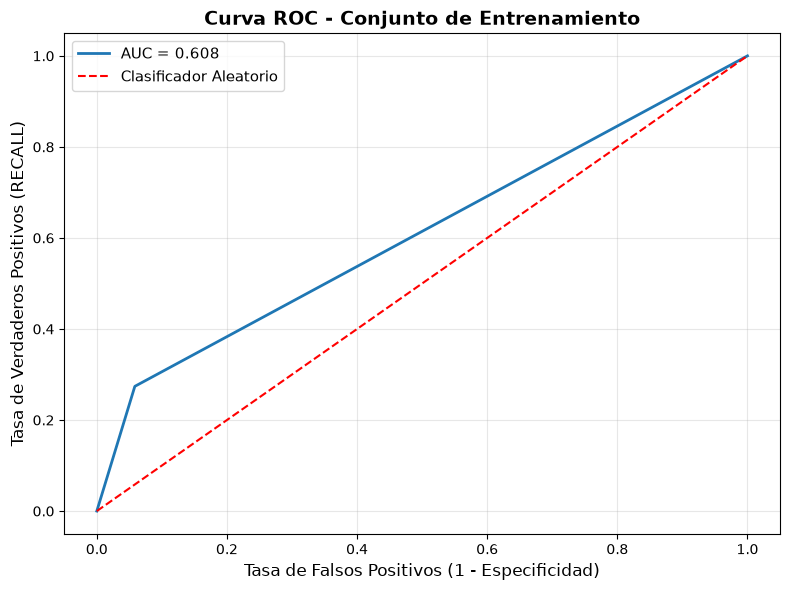

In [29]:
train_auc = roc_auc_score(y_train, pred_train)
fpr_train, tpr_train, _ = roc_curve(y_train, pred_train)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f'AUC = {train_auc:.3f}', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Clasificador Aleatorio')
plt.title('Curva ROC - Conjunto de Entrenamiento', fontsize=14, fontweight='bold')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (RECALL)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Guardar modelo

In [ ]:
joblib.dump(modelo2, "../model/modelo_regresion_lineal.pkl")

## Evaluación del modelo

Hemos obtenido un accuracy del 66,7 % en entrenamiento y del 66,5 % en validación, por lo que vemos que los resultados son muy similares y que no parece haber un sobreajuste importante. También hemos conseguido una precision del 77,5 % en validación, lo que significa que, cuando el modelo predice que una canción llegará al Top 30, suele acertar. Sin embargo, el recall ha sido del 26,1 %, así que todavía se le escapan bastantes canciones que realmente llegan a esa posición. Por otro lado, hemos obtenido un F1-score de 0,391 y un AUC de 0,671. En general, consideramos que hemos conseguido un primer modelo que funciona como punto de partida, aunque todavía tiene margen de mejora, por lo que vamos a compararlo con otros algoritmos para intentar conseguir mejores resultados.